# Train Supply XGBoost Core and Full Models

This Colab notebook trains direct H1–H12 crop-production forecasting models for both supply variants. It uses chronological validation and testing, saves the complete scikit-learn pipelines, and writes all artifacts to Google Drive.

> Important: the current production target is synthetic. The results validate the workflow only and must not be presented as real-world supply accuracy.

## Google Drive input structure

Upload the two generated CSV files using this structure:

```text
MyDrive/demand-forecasting/Dataset/supply/
├── core/supply_horizon_training_dataset.csv
└── full/supply_horizon_training_dataset.csv
```

In [1]:
%pip install -q pandas scikit-learn joblib matplotlib seaborn xgboost

In [2]:
import json
import platform
import shutil
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from google.colab import drive
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

drive.mount('/content/drive')

DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/demand-forecasting')
DRIVE_DATA_ROOT = DRIVE_PROJECT_DIR / 'Dataset' / 'supply'
DRIVE_ARTIFACT_ROOT = DRIVE_PROJECT_DIR / 'artifacts' / 'supply'
LOCAL_ARTIFACT_ROOT = Path('/content/supply_xgboost_artifacts')
VARIANTS = ('core', 'full')
TARGET_COLUMN = 'future_production_kg'
CATEGORICAL_FEATURES = ['crop', 'location', 'origin_season', 'target_season']
EXCLUDED_FEATURES = ['forecast_origin_month', 'target_month', TARGET_COLUMN]
VALIDATION_MONTHS = 3
TEST_MONTHS = 3
RANDOM_STATE = 42

for variant in VARIANTS:
    expected = DRIVE_DATA_ROOT / variant / 'supply_horizon_training_dataset.csv'
    if not expected.exists():
        raise FileNotFoundError(f'Upload the {variant} supply dataset to: {expected}')
    print(f'Found: {expected}')

Mounted at /content/drive
Found: /content/drive/MyDrive/demand-forecasting/Dataset/supply/core/supply_horizon_training_dataset.csv
Found: /content/drive/MyDrive/demand-forecasting/Dataset/supply/full/supply_horizon_training_dataset.csv


In [3]:
def load_and_split(variant):
    path = DRIVE_DATA_ROOT / variant / 'supply_horizon_training_dataset.csv'
    data = pd.read_csv(path, parse_dates=['forecast_origin_month', 'target_month'])
    required = [
        'forecast_origin_month', 'target_month', 'forecast_horizon',
        *CATEGORICAL_FEATURES, TARGET_COLUMN,
    ]
    missing = [column for column in required if column not in data.columns]
    if missing:
        raise ValueError(f'{variant} supply data is missing columns: {missing}')
    if data[required].isna().any().any():
        raise ValueError(f'{variant} supply data contains missing required values.')
    duplicate_keys = ['forecast_origin_month', 'crop', 'location', 'forecast_horizon']
    if data.duplicated(duplicate_keys).any():
        raise ValueError(f'{variant} supply data contains duplicate horizon rows.')

    data = data.sort_values(
        ['target_month', 'forecast_origin_month', 'crop', 'location']
    ).reset_index(drop=True)
    final_month = data['target_month'].max().to_period('M').to_timestamp()
    test_start = final_month - pd.DateOffset(months=TEST_MONTHS - 1)
    validation_start = test_start - pd.DateOffset(months=VALIDATION_MONTHS)

    train = data[data['target_month'] < validation_start].copy()
    validation = data[data['target_month'].between(
        validation_start, test_start - pd.DateOffset(months=1)
    )].copy()
    test = data[data['target_month'] >= test_start].copy()

    for name, frame in {'train': train, 'validation': validation, 'test': test}.items():
        if frame.empty:
            raise ValueError(f'{variant} {name} split is empty.')
        if set(frame['forecast_horizon'].astype(int).unique()) != set(range(1, 13)):
            raise ValueError(f'{variant} {name} split does not contain every H1–H12 horizon.')

    boundaries = {
        'train': (train['target_month'].min(), train['target_month'].max()),
        'validation': (validation['target_month'].min(), validation['target_month'].max()),
        'test': (test['target_month'].min(), test['target_month'].max()),
    }
    return data, train, validation, test, boundaries


def build_pipeline(numeric_features):
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('one_hot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
    ])
    preprocessor = ColumnTransformer(
        [
            ('categorical', categorical_pipeline, CATEGORICAL_FEATURES),
            ('numeric', numeric_pipeline, numeric_features),
        ],
        remainder='drop',
        verbose_feature_names_out=False,
    )
    model = XGBRegressor(
        objective='reg:squarederror',
        n_estimators=500,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=1.0,
        tree_method='hist',
        eval_metric='mae',
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    return Pipeline([('preprocessor', preprocessor), ('model', model)])


def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denominator = np.abs(actual).sum()
    return {
        'mae': float(mean_absolute_error(actual, predicted)),
        'rmse': float(np.sqrt(mean_squared_error(actual, predicted))),
        'wape': float(np.abs(actual - predicted).sum() / denominator) if denominator else np.nan,
        'r2': float(r2_score(actual, predicted)),
    }


def make_prediction_table(frame, predictions, split_name, variant):
    columns = [
        'forecast_origin_month', 'target_month', 'crop', 'location',
        'forecast_horizon', TARGET_COLUMN,
    ]
    output = frame[columns].copy()
    output['xgboost_prediction'] = np.maximum(predictions, 0)
    output['absolute_error'] = (output[TARGET_COLUMN] - output['xgboost_prediction']).abs()
    output['split'] = split_name
    output['model_variant'] = variant
    return output

In [4]:
all_metrics = []
variant_results = {}

for variant in VARIANTS:
    print(f'\nTraining supply XGBoost {variant} variant...')
    data, train, validation, test, boundaries = load_and_split(variant)
    feature_columns = [column for column in data.columns if column not in EXCLUDED_FEATURES]
    numeric_features = [column for column in feature_columns if column not in CATEGORICAL_FEATURES]
    unexpected_text = [
        column for column in numeric_features
        if not pd.api.types.is_numeric_dtype(data[column])
    ]
    if unexpected_text:
        raise ValueError(f'{variant} features need an encoding policy: {unexpected_text}')

    print({
        name: f'{start:%Y-%m} to {end:%Y-%m}'
        for name, (start, end) in boundaries.items()
    })
    print(f'Rows — train: {len(train):,}, validation: {len(validation):,}, test: {len(test):,}')

    validation_pipeline = build_pipeline(numeric_features)
    validation_pipeline.fit(train[feature_columns], train[TARGET_COLUMN])
    validation_predictions = make_prediction_table(
        validation,
        validation_pipeline.predict(validation[feature_columns]),
        'validation',
        variant,
    )

    train_validation = pd.concat([train, validation], ignore_index=True).sort_values('target_month')
    final_pipeline = build_pipeline(numeric_features)
    final_pipeline.fit(train_validation[feature_columns], train_validation[TARGET_COLUMN])
    test_predictions = make_prediction_table(
        test,
        final_pipeline.predict(test[feature_columns]),
        'test',
        variant,
    )

    records = []
    for split_name, predictions in [
        ('validation', validation_predictions),
        ('test', test_predictions),
    ]:
        records.append({
            'model': 'xgboost',
            'model_variant': variant,
            'split': split_name,
            'forecast_horizon': 'overall',
            'rows': len(predictions),
            **calculate_metrics(predictions[TARGET_COLUMN], predictions['xgboost_prediction']),
        })
        for horizon, group in predictions.groupby('forecast_horizon'):
            records.append({
                'model': 'xgboost',
                'model_variant': variant,
                'split': split_name,
                'forecast_horizon': int(horizon),
                'rows': len(group),
                **calculate_metrics(group[TARGET_COLUMN], group['xgboost_prediction']),
            })

    variant_metrics = pd.DataFrame(records)
    all_metrics.append(variant_metrics)

    local_root = LOCAL_ARTIFACT_ROOT / variant
    drive_root = DRIVE_ARTIFACT_ROOT / variant
    model_dir = local_root / 'models'
    prediction_dir = local_root / 'predictions'
    report_dir = local_root / 'reports'
    for directory in (model_dir, prediction_dir, report_dir):
        directory.mkdir(parents=True, exist_ok=True)

    joblib.dump(final_pipeline, model_dir / 'global_xgboost_pipeline.joblib')
    final_pipeline.named_steps['model'].save_model(model_dir / 'global_xgboost_model.json')
    validation_predictions.to_csv(
        prediction_dir / 'xgboost_validation_predictions.csv', index=False
    )
    test_predictions.to_csv(prediction_dir / 'xgboost_test_predictions.csv', index=False)
    variant_metrics.to_csv(report_dir / 'xgboost_metrics.csv', index=False)

    test_overall = next(
        record for record in records
        if record['split'] == 'test' and record['forecast_horizon'] == 'overall'
    )
    metadata = {
        'model': 'global_direct_multi_horizon_supply_xgboost',
        'model_variant': variant,
        'requires_air_quality': variant == 'full',
        'synthetic_training_target': True,
        'target': TARGET_COLUMN,
        'feature_columns': feature_columns,
        'categorical_features': CATEGORICAL_FEATURES,
        'training_data_end': str(train_validation['target_month'].max().date()),
        'test_period': {
            'start': str(test['target_month'].min().date()),
            'end': str(test['target_month'].max().date()),
        },
        'test_metrics': test_overall,
        'parameters': final_pipeline.named_steps['model'].get_params(),
        'versions': {
            'python': platform.python_version(),
            'pandas': pd.__version__,
            'scikit_learn': sklearn.__version__,
            'xgboost': xgboost.__version__,
            'joblib': joblib.__version__,
        },
    }
    (report_dir / 'xgboost_training_metadata.json').write_text(
        json.dumps(metadata, indent=2), encoding='utf-8'
    )

    for source in local_root.rglob('*'):
        if source.is_file():
            destination = drive_root / source.relative_to(local_root)
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(source, destination)

    variant_results[variant] = {
        'test': test_predictions,
        'metrics': variant_metrics,
    }
    print(f'Saved {variant} artifacts to: {drive_root}')

comparison = pd.concat(all_metrics, ignore_index=True)
print('\nSUPPLY XGBOOST TRAINING COMPLETE')


Training supply XGBoost core variant...
{'train': '2022-02 to 2025-06', 'validation': '2025-07 to 2025-09', 'test': '2025-10 to 2025-12'}
Rows — train: 19,170, validation: 1,620, test: 1,620
Saved core artifacts to: /content/drive/MyDrive/demand-forecasting/artifacts/supply/core

Training supply XGBoost full variant...
{'train': '2022-02 to 2025-06', 'validation': '2025-07 to 2025-09', 'test': '2025-10 to 2025-12'}
Rows — train: 19,170, validation: 1,620, test: 1,620
Saved full artifacts to: /content/drive/MyDrive/demand-forecasting/artifacts/supply/full

SUPPLY XGBOOST TRAINING COMPLETE


In [5]:
overall_test = comparison[
    (comparison['split'] == 'test')
    & (comparison['forecast_horizon'] == 'overall')
].copy()
overall_test['wape_percent'] = overall_test['wape'] * 100
display(
    overall_test[
        ['model_variant', 'rows', 'mae', 'rmse', 'wape_percent', 'r2']
    ].sort_values('mae').style.format({
        'mae': '{:,.2f}',
        'rmse': '{:,.2f}',
        'wape_percent': '{:.2f}%',
        'r2': '{:.3f}',
    })
)

,model_variant,rows,mae,rmse,wape_percent,r2
13,core,1620,438.46,563.18,16.68%,0.684
39,full,1620,438.96,563.95,16.70%,0.683


/tmp/ipykernel_1591/2818665718.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=overall_test, x='model_variant', y=metric, ax=axis, palette='Set2')
/tmp/ipykernel_1591/2818665718.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=overall_test, x='model_variant', y=metric, ax=axis, palette='Set2')
/tmp/ipykernel_1591/2818665718.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=overall_test, x='model_variant', y=metric, ax=axis, palette='Set2')


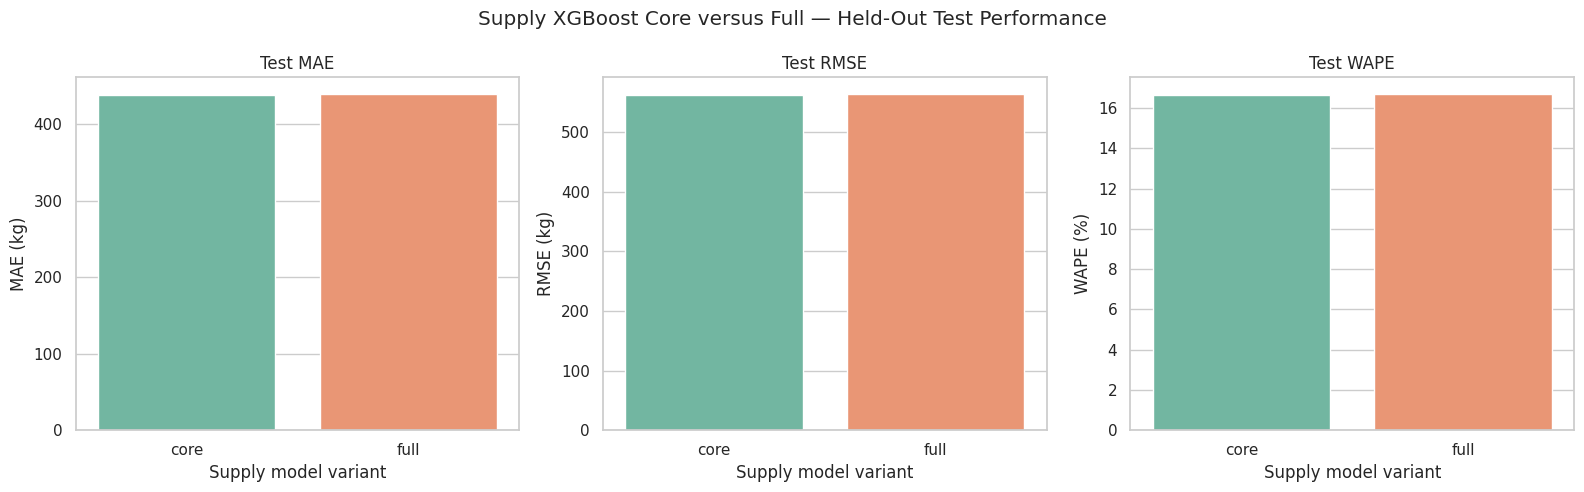

/tmp/ipykernel_1591/2818665718.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=overall_test, x='model_variant', y='r2', palette='Set2')


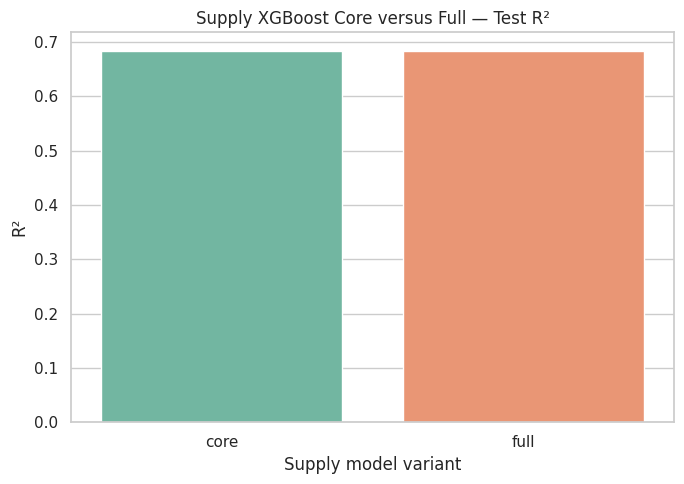

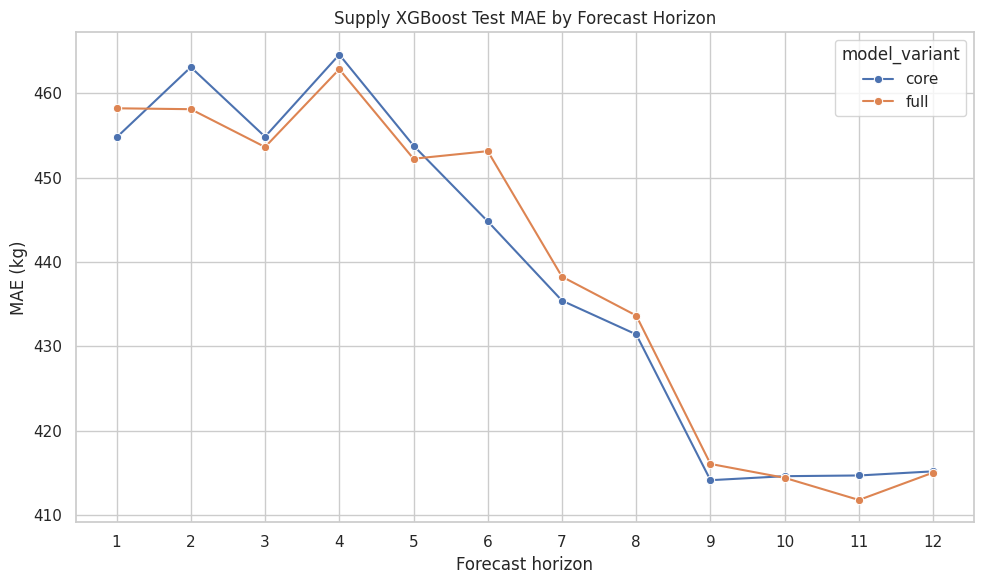

Comparison reports saved to: /content/drive/MyDrive/demand-forecasting/artifacts/supply/reports


In [6]:
sns.set_theme(style='whitegrid')
figure_dir = LOCAL_ARTIFACT_ROOT / 'reports'
figure_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for axis, metric, title, label in [
    (axes[0], 'mae', 'Test MAE', 'MAE (kg)'),
    (axes[1], 'rmse', 'Test RMSE', 'RMSE (kg)'),
    (axes[2], 'wape_percent', 'Test WAPE', 'WAPE (%)'),
]:
    sns.barplot(data=overall_test, x='model_variant', y=metric, ax=axis, palette='Set2')
    axis.set_title(title)
    axis.set_xlabel('Supply model variant')
    axis.set_ylabel(label)
plt.suptitle('Supply XGBoost Core versus Full — Held-Out Test Performance')
plt.tight_layout()
error_figure = figure_dir / 'xgboost_core_full_error_comparison.png'
plt.savefig(error_figure, dpi=200, bbox_inches='tight')
plt.show()

plt.figure(figsize=(7, 5))
sns.barplot(data=overall_test, x='model_variant', y='r2', palette='Set2')
plt.title('Supply XGBoost Core versus Full — Test R²')
plt.xlabel('Supply model variant')
plt.ylabel('R²')
plt.tight_layout()
r2_figure = figure_dir / 'xgboost_core_full_r2_comparison.png'
plt.savefig(r2_figure, dpi=200, bbox_inches='tight')
plt.show()

horizon_metrics = comparison[
    (comparison['split'] == 'test')
    & (comparison['forecast_horizon'] != 'overall')
].copy()
horizon_metrics['forecast_horizon'] = horizon_metrics['forecast_horizon'].astype(int)
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=horizon_metrics,
    x='forecast_horizon',
    y='mae',
    hue='model_variant',
    marker='o',
)
plt.title('Supply XGBoost Test MAE by Forecast Horizon')
plt.xlabel('Forecast horizon')
plt.ylabel('MAE (kg)')
plt.xticks(range(1, 13))
plt.tight_layout()
horizon_figure = figure_dir / 'xgboost_test_mae_by_horizon.png'
plt.savefig(horizon_figure, dpi=200, bbox_inches='tight')
plt.show()

drive_report_dir = DRIVE_ARTIFACT_ROOT / 'reports'
drive_report_dir.mkdir(parents=True, exist_ok=True)
for figure in (error_figure, r2_figure, horizon_figure):
    shutil.copy2(figure, drive_report_dir / figure.name)
comparison.to_csv(drive_report_dir / 'xgboost_core_full_metrics.csv', index=False)
print(f'Comparison reports saved to: {drive_report_dir}')

## Saved outputs

For each variant, the notebook saves:

- `models/global_xgboost_pipeline.joblib` — complete preprocessing and prediction pipeline.
- `models/global_xgboost_model.json` — native XGBoost regressor.
- `predictions/xgboost_validation_predictions.csv`.
- `predictions/xgboost_test_predictions.csv`.
- `reports/xgboost_metrics.csv`.
- `reports/xgboost_training_metadata.json`.

The shared `artifacts/supply/reports` directory contains the core/full comparison table and figures. Keep the pipeline and metadata together because loading a joblib model with incompatible package versions can fail.